# Lab 3 - Quantization, DCT and JPEG-like Coding

Scalar quantization and a custom DCT-based codec are compared using visual outputs, image-quality metrics and encoded file sizes. Saved results are retained; the custom `.ljc` bitstream is not a JPEG file.

[Lab notes and figures](README.md)


In [1]:
# Setup: install only missing packages (Colab normally already has these).
import sys, subprocess, importlib.util
required = {'numpy':'numpy', 'matplotlib':'matplotlib', 'PIL':'pillow',
            'scipy':'scipy', 'skimage':'scikit-image', 'pandas':'pandas', 'IPython':'ipython'}
missing = [package for module, package in required.items() if importlib.util.find_spec(module) is None]
if missing:
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *missing])
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from PIL import Image, ImageOps
from scipy.fft import dctn, idctn
from skimage import data
from skimage.metrics import structural_similarity
from pathlib import Path
from collections import Counter
import json, math, heapq, struct, shutil, platform, importlib.metadata
from IPython.display import display

# SETTINGS — defaults work with Run all.
CUSTOM_IMAGE_PATHS = []  # Example: ['/content/my_photo.jpg']
MAX_SIDE = 512          # preserves aspect ratio; avoids large output files
QUALITY_SCALES = [0.5, 1, 2, 4, 8, 16]
AUTO_DOWNLOAD = True    # Colab downloads the ZIP at the end
OUT = Path('DT096A_Lab3_results')
OUT.mkdir(exist_ok=True)
for folder in ['figures','images','tables','bitstreams','subjective']:
    (OUT / folder).mkdir(exist_ok=True)
plt.rcParams.update({'figure.dpi':110, 'font.size':10})
np.random.seed(96)
print('Ready. CPU execution; no GPU required.')

Ready. CPU execution; no GPU required.


## Section 2 — Images and experiment records
Two standard images provide smooth areas, edges, and textures. All processing uses 8-bit grayscale. Uploaded images are converted with Pillow and resized only when larger than `MAX_SIDE`. The exact processed originals are saved. Section 7 reports both the raw grayscale compression ratio and the stored reference PNG ratio; these are different baselines.

In [2]:
images = {}
image_records = []
def add_image(name, source, source_description, source_bytes=None):
    im = ImageOps.exif_transpose(source).convert('L')
    old_size = im.size
    im.thumbnail((MAX_SIDE, MAX_SIDE), Image.Resampling.LANCZOS)
    x = np.asarray(im, dtype=np.uint8).copy()
    images[name] = x
    ref = OUT / 'images' / f'{name}_original.png'
    Image.fromarray(x).save(ref)
    image_records.append({'image':name, 'source':source_description,
        'input_width':old_size[0], 'input_height':old_size[1],
        'processed_width':x.shape[1], 'processed_height':x.shape[0],
        'source_file_bytes':source_bytes, 'reference_png_bytes':ref.stat().st_size,
        'raw_grayscale_bytes':x.size})
add_image('camera', Image.fromarray(data.camera()), 'skimage.data.camera')
add_image('astronaut', Image.fromarray(data.astronaut()), 'skimage.data.astronaut, converted to grayscale')
for i, path in enumerate(CUSTOM_IMAGE_PATHS):
    p = Path(path)
    if not p.is_file():
        raise FileNotFoundError(f'Image not found: {p}. Upload it or correct CUSTOM_IMAGE_PATHS.')
    with Image.open(p) as im:
        add_image(f'personal_{i+1}', im.copy(), str(p), p.stat().st_size)
pd.DataFrame(image_records).to_csv(OUT/'tables/image_sources.csv', index=False)
display(pd.DataFrame(image_records))
def savefig(name):
    plt.tight_layout()
    plt.savefig(OUT/'figures'/f'{name}.png', dpi=160, bbox_inches='tight')
    plt.show()
    plt.close()
def save_image(x, name):
    Image.fromarray(np.asarray(x, dtype=np.uint8)).save(OUT/'images'/f'{name}.png')
versions = {p:importlib.metadata.version(p) for p in required.values()}
(OUT/'environment.json').write_text(json.dumps({'python':platform.python_version(),
    'packages':versions, 'settings':{'MAX_SIDE':MAX_SIDE,'QUALITY_SCALES':QUALITY_SCALES},
    'external_support':'NumPy; Pillow for image I/O; SciPy orthonormal DCT/IDCT; scikit-image bundled images and SSIM; Matplotlib; pandas. Quantizer and Huffman/zigzag/RLE/bitstream code implemented in this notebook. Notebook prepared with ChatGPT assistance.'}, indent=2))

,image,source,input_width,input_height,processed_width,processed_height,source_file_bytes,reference_png_bytes,raw_grayscale_bytes
0,camera,skimage.data.camera,512,512,512,512,None,142314,262144
1,astronaut,"skimage.data.astronaut, converted to grayscale",512,512,512,512,None,139052,262144


609

## Section 3, Tasks 1–2 — Uniform scalar quantization
`quantize(image, bits)` uses equal-width input bins and reconstructs at each bin midpoint. Thus 1 bit gives two intensity levels, 2 bits gives four, etc. This is a **midpoint** convention, so even a constant extreme value may change. Error images use one shared display scale (0–128); histograms use fixed 0–255 axes. Errors and MSE are calculated in floating point to prevent unsigned-integer overflow.

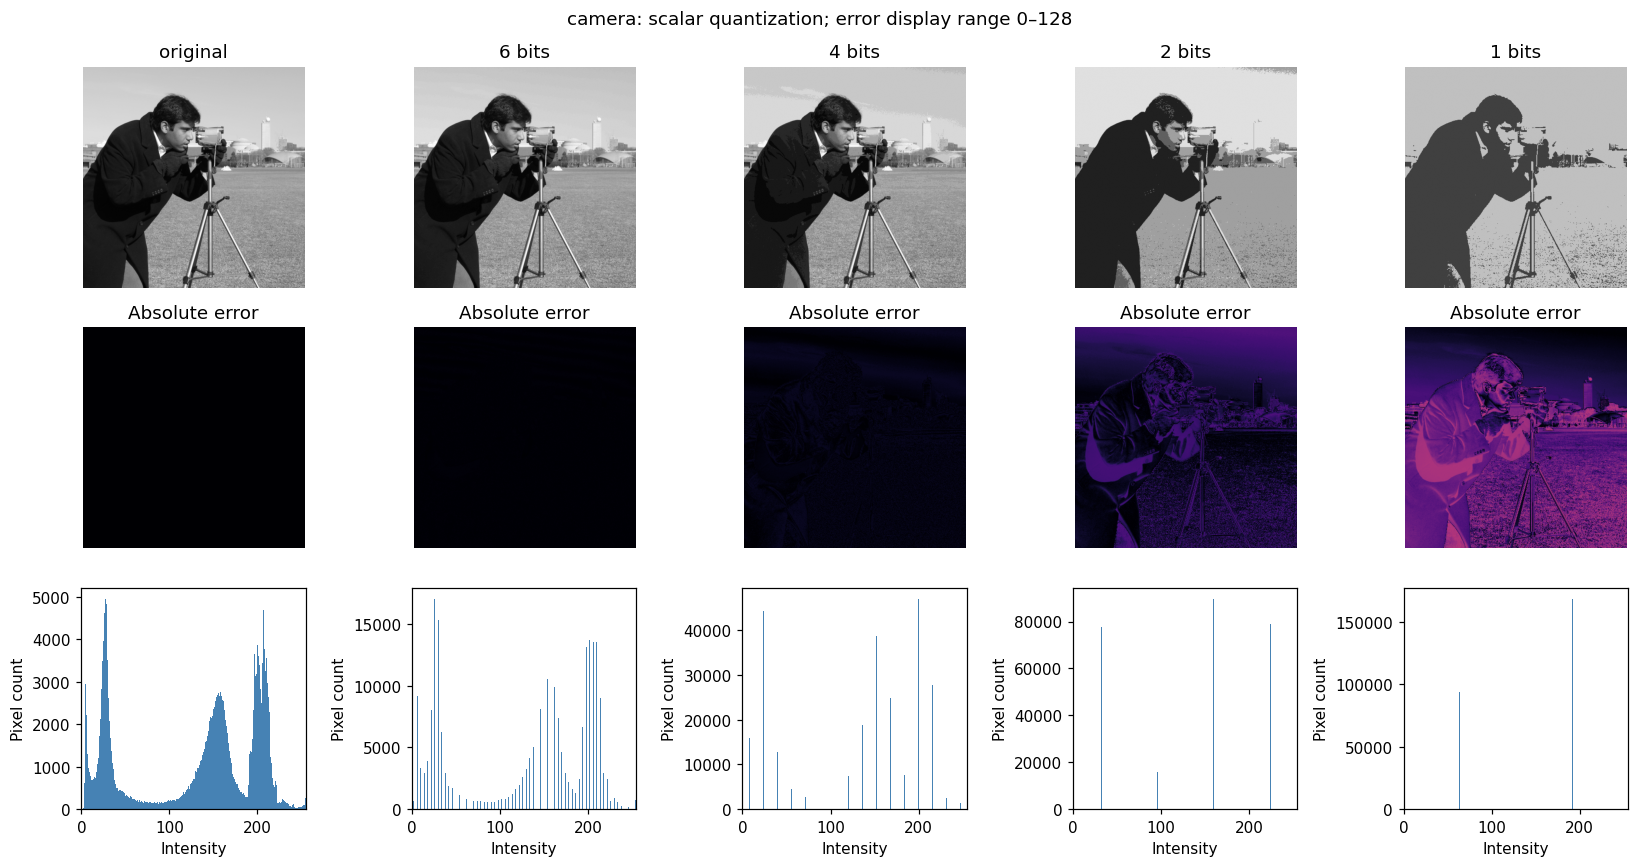

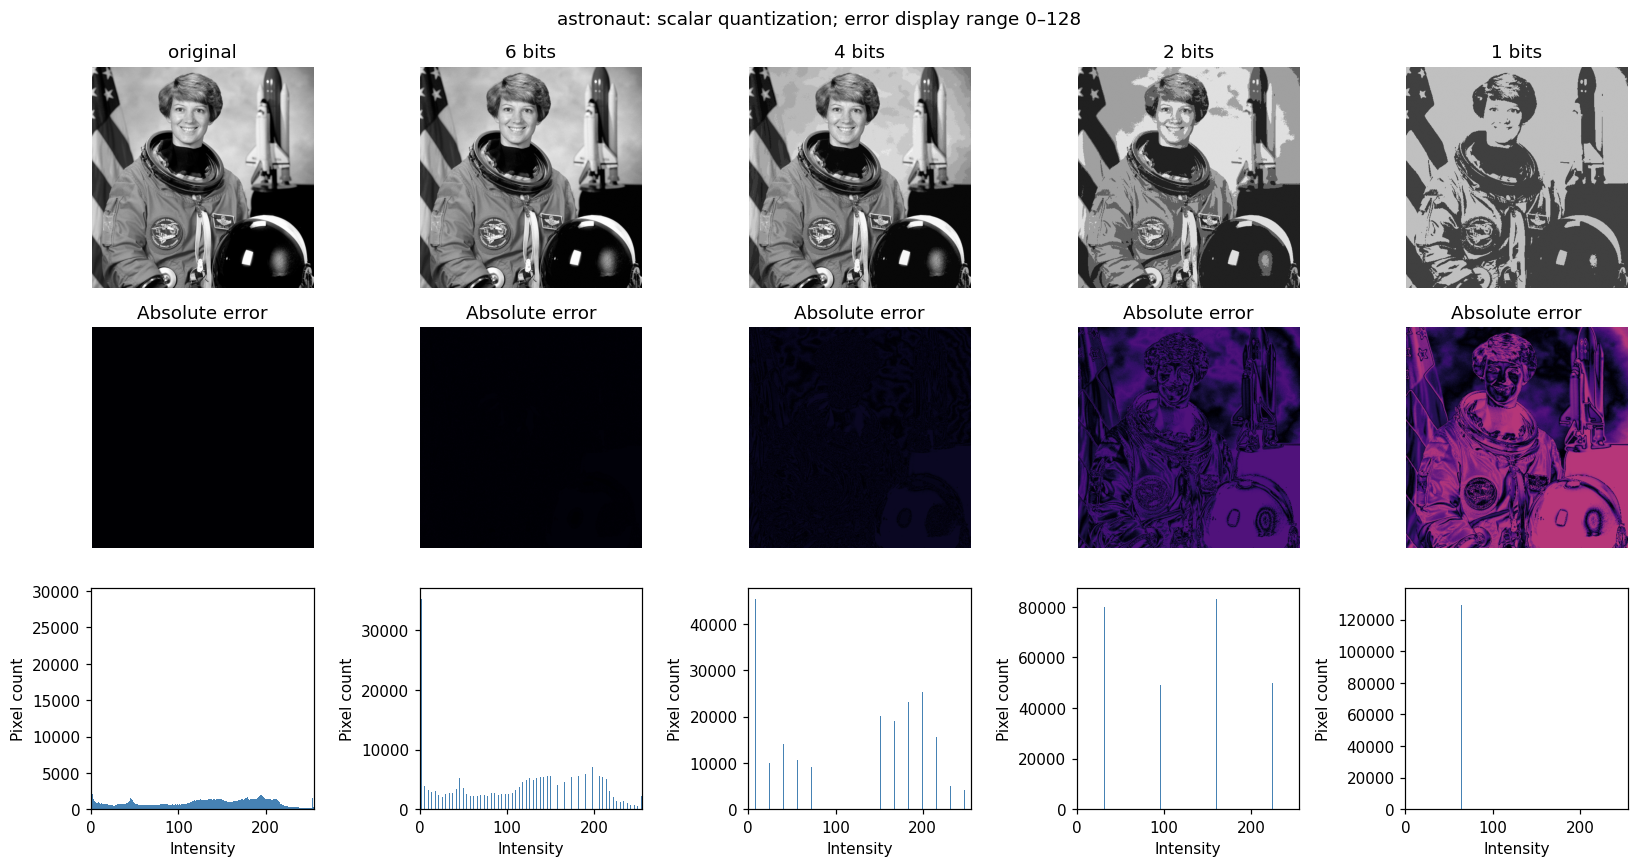

,image,bits,allowed_levels,observed_levels,MSE,PSNR_dB,MAE,max_abs_error
0,camera,6,64,64,1.5137,46.3303,1.0053,2.0
1,camera,4,16,16,20.7682,34.9568,3.9209,8.0
2,camera,2,4,4,282.0384,23.6277,14.0730,32.0
3,camera,1,2,2,1229.2164,17.2345,30.7997,64.0
4,astronaut,6,64,64,1.7480,45.7054,1.0970,2.0
5,astronaut,4,16,16,26.6498,33.8739,4.5060,8.0
6,astronaut,2,4,4,453.0039,21.5698,18.9283,32.0
7,astronaut,1,2,2,1634.4480,15.9971,34.4601,64.0


In [3]:
def mse(original, reconstructed):
    return float(np.mean((original.astype(np.float64)-reconstructed.astype(np.float64))**2))
def psnr(original, reconstructed):
    e = mse(original, reconstructed)
    return float('inf') if e == 0 else float(10*np.log10(255.0**2/e))
def ssim(original, reconstructed):
    return float(structural_similarity(original, reconstructed, data_range=255))
def quantize(image, bits):
    if bits not in range(1,9):
        raise ValueError('bits must be an integer from 1 to 8')
    step = 256.0/(2**bits)
    indices = np.floor(image.astype(float)/step)
    return np.clip(np.floor((indices+0.5)*step),0,255).astype(np.uint8)
scalar_rows=[]
for name,x in images.items():
    variants = [('original',x)] + [(f'{b} bits',quantize(x,b)) for b in [6,4,2,1]]
    fig,axs=plt.subplots(3,5,figsize=(15,8))
    for j,(label,y) in enumerate(variants):
        axs[0,j].imshow(y,cmap='gray',vmin=0,vmax=255)
        axs[0,j].set_title(label); axs[0,j].axis('off')
        error=np.abs(x.astype(float)-y.astype(float))
        artist=axs[1,j].imshow(error,cmap='magma',vmin=0,vmax=128)
        axs[1,j].set_title('Absolute error'); axs[1,j].axis('off')
        axs[2,j].hist(y.ravel(),bins=np.arange(257)-0.5,color='steelblue')
        axs[2,j].set(xlim=(0,255),xlabel='Intensity',ylabel='Pixel count')
        if j:
            bits=[6,4,2,1][j-1]
            scalar_rows.append({'image':name,'bits':bits,'allowed_levels':2**bits,
                'observed_levels':len(np.unique(y)), 'MSE':mse(x,y),'PSNR_dB':psnr(x,y),
                'MAE':float(error.mean()),'max_abs_error':float(error.max())})
            save_image(y,f'{name}_scalar_{bits}bit')
            save_image(error,f'{name}_scalar_{bits}bit_error')
    fig.suptitle(f'{name}: scalar quantization; error display range 0–128')
    savefig(f'S3_{name}_quantization')
scalar_table=pd.DataFrame(scalar_rows)
scalar_table.to_csv(OUT/'tables/S3_scalar_quantization.csv',index=False)
display(scalar_table.round(4))

## Section 4, Tasks 1–3 — Block DCT, quantization, reconstruction
Pipeline: grayscale → edge padding to a multiple of 8 → subtract 128 → orthonormal 8×8 DCT → round(C/Q) → multiply by Q → inverse DCT → add 128 → round/clip → crop to the original dimensions.

The transform is reversible apart from floating-point precision; quantization discards information. The JPEG-style base matrix uses stronger quantization for higher frequencies. This is a simplified grayscale codec, **not a standard JPEG file**. `q` here is a matrix scale: larger q means coarser quantization; it is not a JPEG quality percentage.

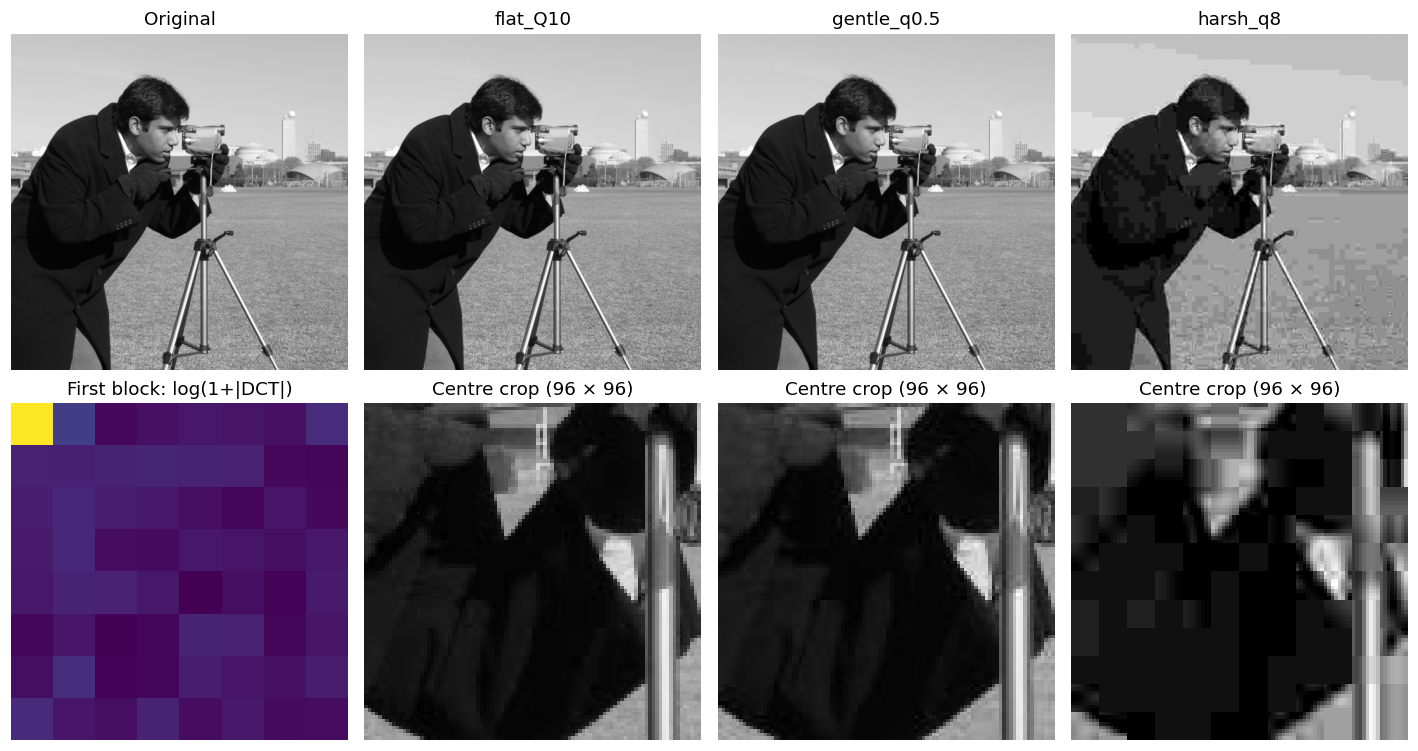

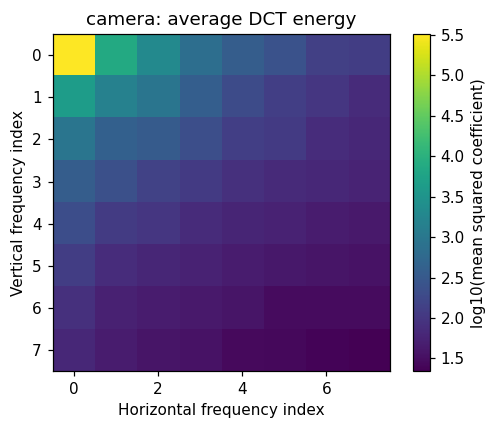

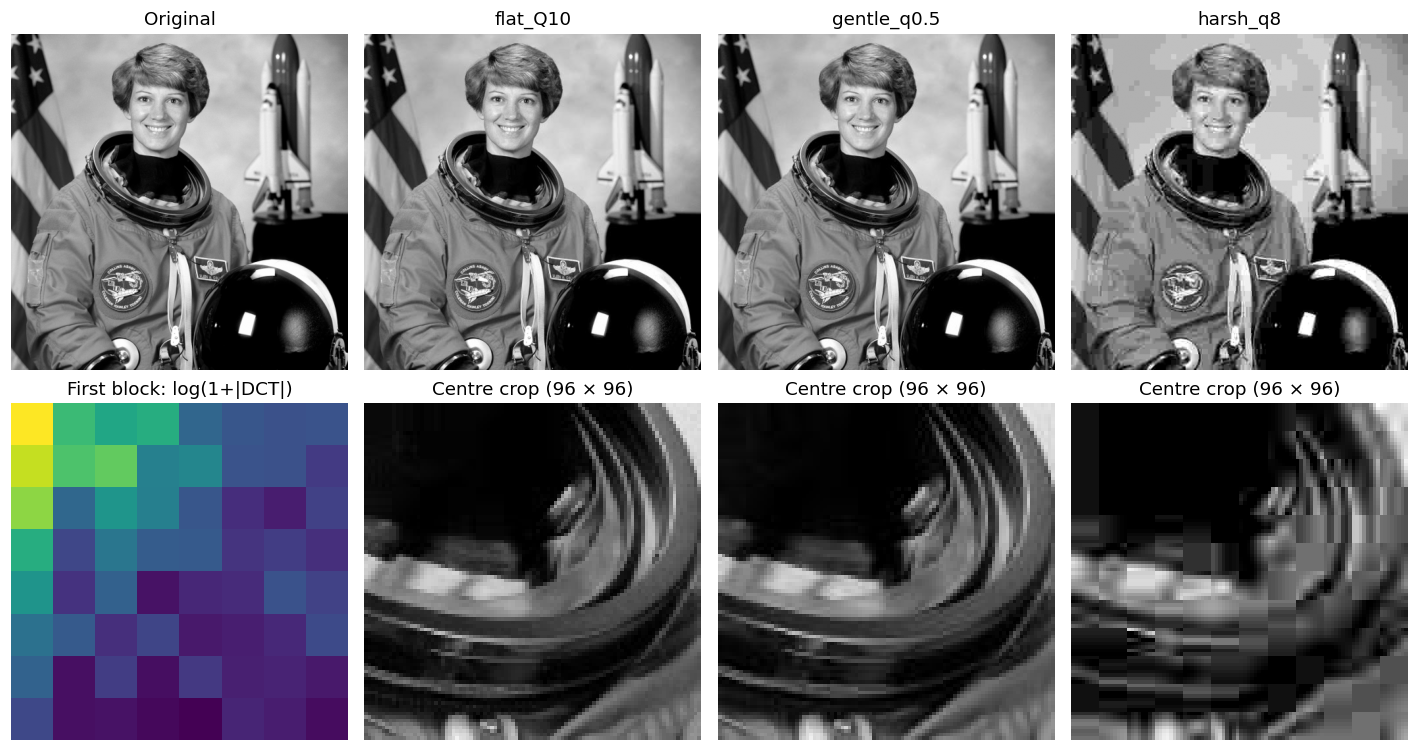

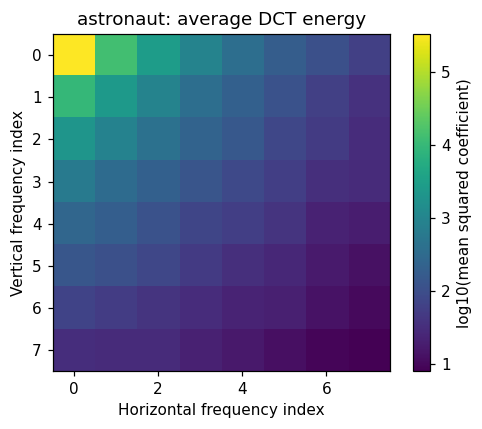

,image,matrix,MSE,PSNR_dB,SSIM,zero_fraction
0,camera,flat_Q10,4.6765,41.4316,0.9787,0.7012
1,camera,gentle_q0.5,19.9919,35.1223,0.9489,0.8120
2,camera,harsh_q8,129.5965,27.0049,0.7143,0.9727
3,astronaut,flat_Q10,4.6406,41.4651,0.9781,0.7663
4,astronaut,gentle_q0.5,11.3972,37.5628,0.9712,0.8244
5,astronaut,harsh_q8,126.9013,27.0961,0.8063,0.9630


In [4]:
BASE_Q=np.array([
 [16,11,10,16,24,40,51,61], [12,12,14,19,26,58,60,55],
 [14,13,16,24,40,57,69,56], [14,17,22,29,51,87,80,62],
 [18,22,37,56,68,109,103,77], [24,35,55,64,81,104,113,92],
 [49,64,78,87,103,121,120,101], [72,92,95,98,112,100,103,99]],dtype=float)
def scaled_q(q, base=BASE_Q):
    return np.maximum(1,np.rint(base*q)).astype(np.int32)
def dct_blocks(x):
    h,w=x.shape
    padded=np.pad(x,((0,(-h)%8),(0,(-w)%8)),mode='edge').astype(float)-128
    hp,wp=padded.shape
    blocks=padded.reshape(hp//8,8,wp//8,8).transpose(0,2,1,3)
    return dctn(blocks,axes=(-2,-1),norm='ortho')
def quantize_dct(coeffs,Q):
    return np.rint(coeffs/Q).astype(np.int32)
def reconstruct(k,Q,shape):
    blocks=idctn(k*Q,axes=(-2,-1),norm='ortho')+128
    image=blocks.transpose(0,2,1,3).reshape(k.shape[0]*8,k.shape[1]*8)
    return np.clip(np.rint(image[:shape[0],:shape[1]]),0,255).astype(np.uint8)
DCTS={name:dct_blocks(x) for name,x in images.items()}
transform_rows=[]
for name,x in images.items():
    configs={'flat_Q10':np.full((8,8),10,dtype=int),
             'gentle_q0.5':scaled_q(.5),'harsh_q8':scaled_q(8)}
    fig,axs=plt.subplots(2,4,figsize=(13,7))
    axs[0,0].imshow(x,cmap='gray',vmin=0,vmax=255); axs[0,0].set_title('Original')
    axs[1,0].imshow(np.log1p(np.abs(DCTS[name][0,0])),cmap='viridis')
    axs[1,0].set_title('First block: log(1+|DCT|)')
    for j,(label,Q) in enumerate(configs.items(),1):
        k=quantize_dct(DCTS[name],Q); y=reconstruct(k,Q,x.shape)
        axs[0,j].imshow(y,cmap='gray',vmin=0,vmax=255); axs[0,j].set_title(label)
        # Same crop for every setting; no contrast adjustment.
        h,w=x.shape; cy,cx=h//2,w//2
        crop=y[max(0,cy-48):cy+48,max(0,cx-48):cx+48]
        axs[1,j].imshow(crop,cmap='gray',vmin=0,vmax=255,interpolation='nearest')
        axs[1,j].set_title('Centre crop (96 × 96)')
        transform_rows.append({'image':name,'matrix':label,'MSE':mse(x,y),
            'PSNR_dB':psnr(x,y),'SSIM':ssim(x,y),'zero_fraction':float(np.mean(k==0))})
        save_image(y,f'{name}_{label}')
        np.savetxt(OUT/'tables'/f'S4_{label}_matrix.csv',Q,delimiter=',',fmt='%d')
    for ax in axs.ravel(): ax.axis('off')
    savefig(f'S4_{name}_transform')
    energy=np.mean(DCTS[name]**2,axis=(0,1))
    plt.figure(figsize=(5,4)); plt.imshow(np.log10(energy+1e-9),cmap='viridis')
    plt.colorbar(label='log10(mean squared coefficient)')
    plt.xlabel('Horizontal frequency index'); plt.ylabel('Vertical frequency index')
    plt.title(f'{name}: average DCT energy')
    savefig(f'S4_{name}_energy')
transform_table=pd.DataFrame(transform_rows)
transform_table.to_csv(OUT/'tables/S4_transform.csv',index=False)
display(transform_table.round(4))

## Section 5, Tasks 1–3; Section 6, Task 1 — Rate, PSNR, and SSIM
Entropy is calculated from a pooled histogram of signed quantized DCT coefficients. Estimated bpp = entropy × number of padded coefficients / number of original pixels. It is an idealized marginal-entropy estimate, excluding metadata and symbol dependencies. Section 7 separately measures actual encoded bytes.

Higher PSNR/SSIM generally indicates better fidelity. Agreement for this experiment does not prove they always agree; disagreements, if present, are recorded rather than assumed.

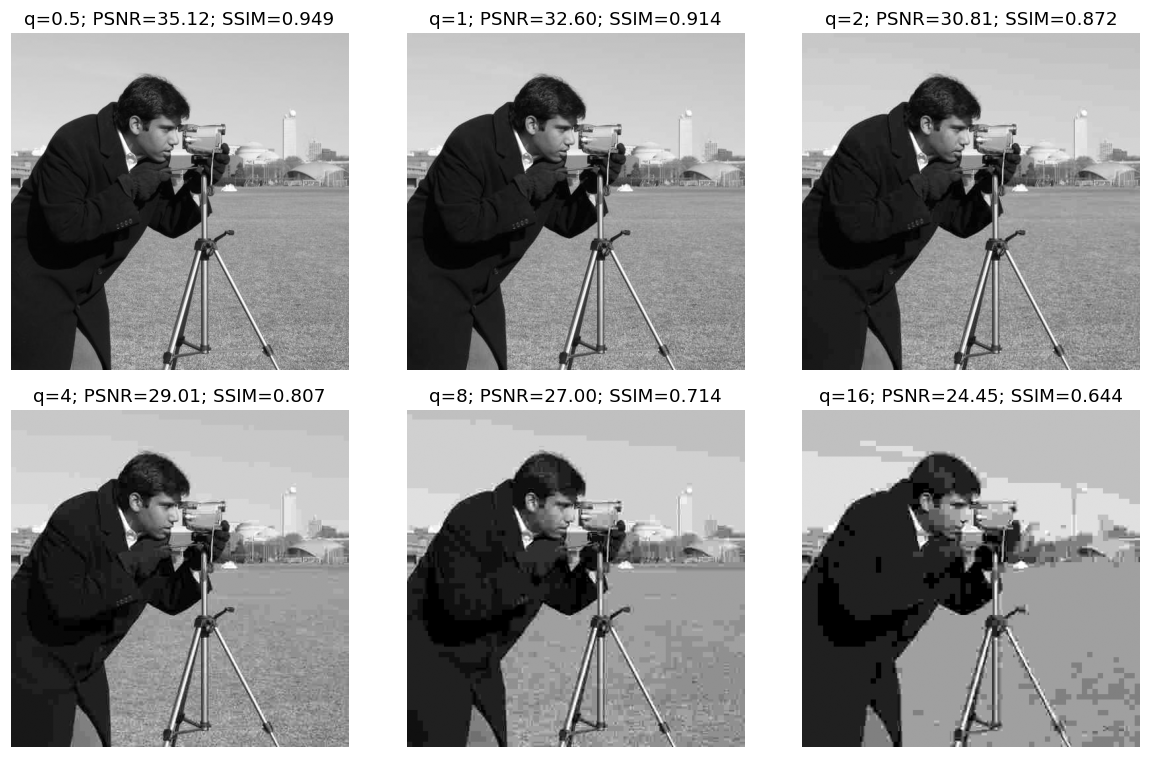

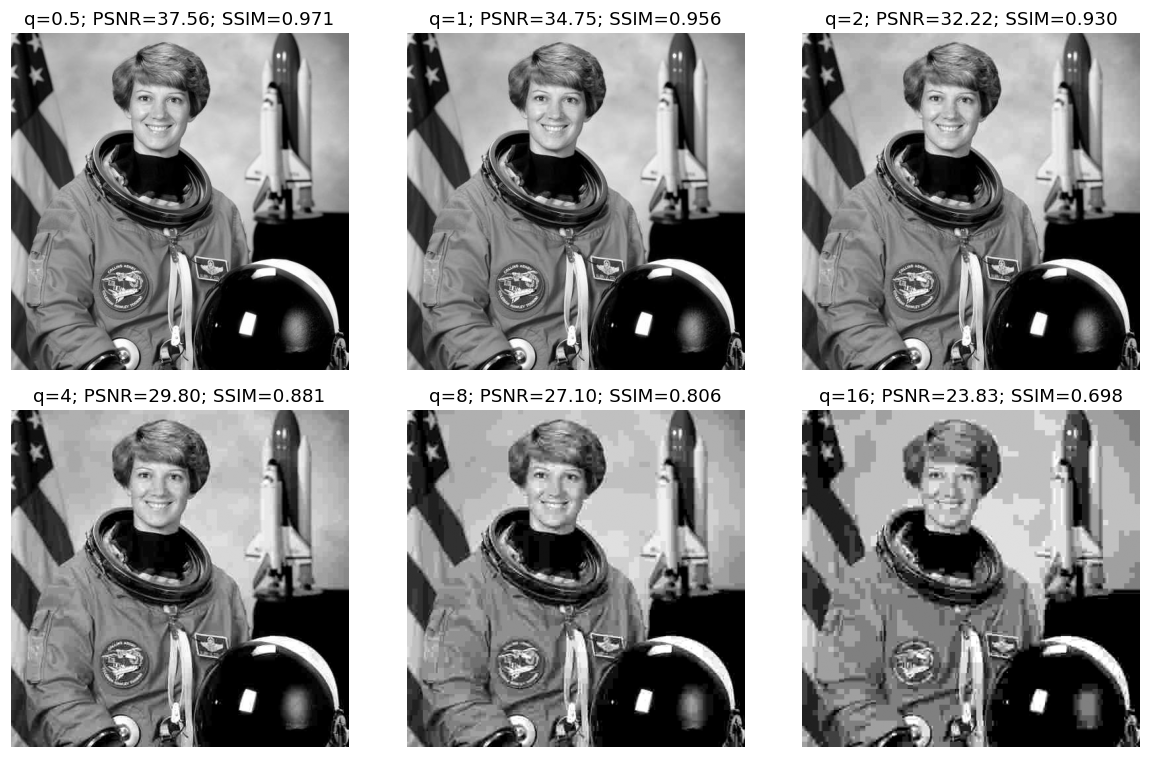

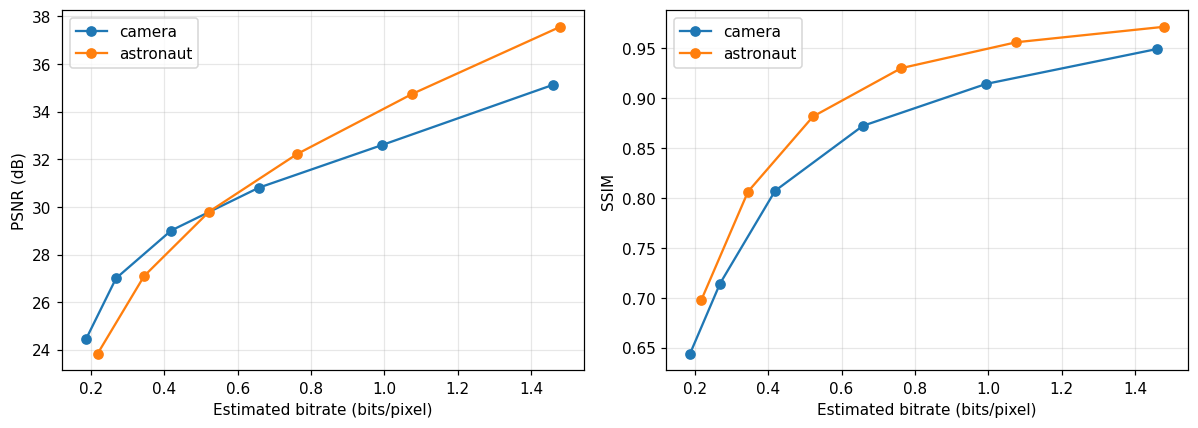

,image,q_scale,entropy_bits_per_coefficient,estimated_bpp,MSE,PSNR_dB,SSIM,zero_fraction,coefficient_count,original_pixel_count
0,camera,0.5,1.4596,1.4596,19.9919,35.1223,0.9489,0.8120,262144,262144
1,camera,1.0,0.9942,0.9942,35.7372,32.5996,0.9140,0.8797,262144,262144
2,camera,2.0,0.6579,0.6579,53.9984,30.8070,0.8720,0.9252,262144,262144
3,camera,4.0,0.4187,0.4187,81.7072,29.0082,0.8071,0.9559,262144,262144
4,camera,8.0,0.2685,0.2685,129.5965,27.0049,0.7143,0.9727,262144,262144
5,camera,16.0,0.1865,0.1865,233.5071,24.4478,0.6440,0.9805,262144,262144
6,astronaut,0.5,1.4800,1.4800,11.3972,37.5628,0.9712,0.8244,262144,262144
7,astronaut,1.0,1.0765,1.0765,21.8012,34.7460,0.9557,0.8758,262144,262144
8,astronaut,2.0,0.7626,0.7626,38.9657,32.2240,0.9298,0.9143,262144,262144
9,astronaut,4.0,0.5223,0.5223,68.0552,29.8022,0.8815,0.9429,262144,262144


PSNR/SSIM ranking reversals: None in the tested matrix-scale sweep.


In [5]:
def entropy(values):
    _,counts=np.unique(values,return_counts=True)
    p=counts/counts.sum()
    return float(-np.sum(p*np.log2(p)))
rd_rows=[]
for name,x in images.items():
    fig,axs=plt.subplots(2,3,figsize=(11,7))
    for q,ax in zip(QUALITY_SCALES,axs.ravel()):
        Q=scaled_q(q); k=quantize_dct(DCTS[name],Q); y=reconstruct(k,Q,x.shape)
        H=entropy(k)
        rd_rows.append({'image':name,'q_scale':q,'entropy_bits_per_coefficient':H,
            'estimated_bpp':H*k.size/x.size,'MSE':mse(x,y),'PSNR_dB':psnr(x,y),
            'SSIM':ssim(x,y),'zero_fraction':float(np.mean(k==0)),
            'coefficient_count':int(k.size),'original_pixel_count':int(x.size)})
        ax.imshow(y,cmap='gray',vmin=0,vmax=255); ax.axis('off')
        ax.set_title(f'q={q}; PSNR={psnr(x,y):.2f}; SSIM={ssim(x,y):.3f}')
        save_image(y,f'{name}_rd_q{q}')
    savefig(f'S5_{name}_reconstructions')
rd_table=pd.DataFrame(rd_rows)
rd_table.to_csv(OUT/'tables/S5_S6_rate_distortion.csv',index=False)
fig,axs=plt.subplots(1,2,figsize=(11,4))
for name in images:
    t=rd_table[rd_table.image==name].sort_values('estimated_bpp')
    for ax,col,label in zip(axs,['PSNR_dB','SSIM'],['PSNR (dB)','SSIM']):
        ax.plot(t.estimated_bpp,t[col],'-o',label=name)
        ax.set(xlabel='Estimated bitrate (bits/pixel)',ylabel=label)
        ax.grid(alpha=.3); ax.legend()
savefig('S5_S6_rate_distortion_curves')
display(rd_table.round(4))
disagreements=[]
for name in images:
    rows=rd_table[rd_table.image==name].to_dict('records')
    for i,a in enumerate(rows):
        for b in rows[i+1:]:
            if (a['PSNR_dB']-b['PSNR_dB'])*(a['SSIM']-b['SSIM'])<0:
                disagreements.append({'image':name,'q_a':a['q_scale'],'q_b':b['q_scale']})
(OUT/'tables/metric_disagreements.json').write_text(json.dumps(disagreements,indent=2))
print('PSNR/SSIM ranking reversals:',disagreements or 'None in the tested matrix-scale sweep.')

## Section 6, Task 2 — Real subjective assessment
The notebook searches for two reconstructions near **30 dB**, one using a flat matrix and one using a frequency-weighted matrix. The measured PSNR gap is reported. Different matrices can change the artifact balance, but visually inspect the selected images: different dominant artifacts are **not guaranteed**. If needed, choose another source image or adjust the matrix/target and rerun this section.

Show **only** `subjective/blind_comparison.png` (or the four labeled PNGs) to a few classmates at the same size. Ask for overall fidelity/quality, best to worst, using each rank 1–4 exactly once (1 = best). Do not reveal the condition key or metric values beforehand. Record one row per participant in `rankings_template.csv`; leave blanks until someone actually responds. Use anonymous IDs such as P1. The CSV is included in the ZIP and can be sent back separately. If it is filled in this runtime, rerun this cell and the final export cell to include the summary.

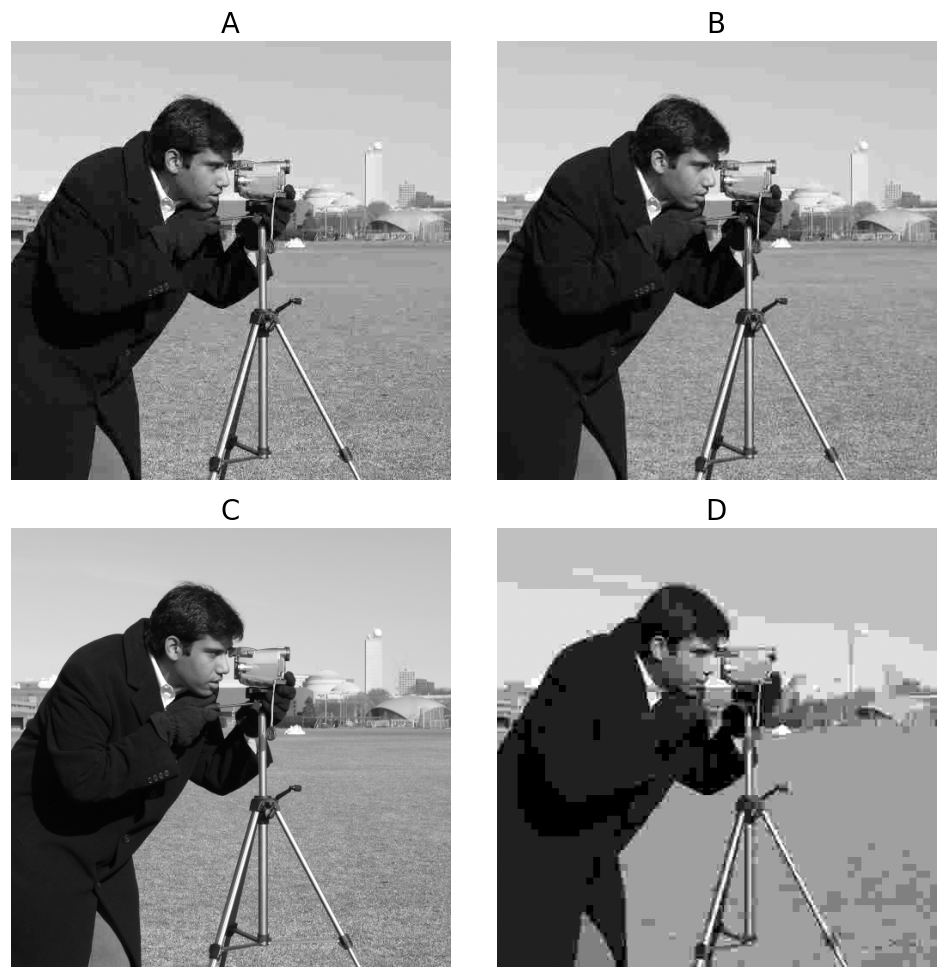

Matched-pair PSNR gap: 0.146 dB. Inspect the artifacts before using the comparison.
PENDING: no real rankings entered. Do not claim subjective results in the report.


In [6]:
subject_name=next(iter(images))
x=images[subject_name]; coeff=DCTS[subject_name]
TARGET_PSNR=30.0
candidates=[]
for matrix_name,base in [('flat',np.full((8,8),16.0)),('weighted',BASE_Q)]:
    best=None
    for scale in np.geomspace(.15,24,100):
        Q=scaled_q(scale,base); y=reconstruct(quantize_dct(coeff,Q),Q,x.shape)
        score=abs(psnr(x,y)-TARGET_PSNR)
        if best is None or score<best[0]: best=(score,y,Q,float(scale))
    candidates.append((matrix_name,best[1],best[2],best[3]))
heavyQ=scaled_q(16)
conditions=[('original',x,None,None),
            (candidates[0][0],candidates[0][1],candidates[0][2],candidates[0][3]),
            (candidates[1][0],candidates[1][1],candidates[1][2],candidates[1][3]),
            ('heavy_q16',reconstruct(quantize_dct(coeff,heavyQ),heavyQ,x.shape),heavyQ,16)]
order=np.random.default_rng(96).permutation(4)
key=[]
fig,axs=plt.subplots(2,2,figsize=(9,9))
for label,idx,ax in zip('ABCD',order,axs.ravel()):
    condition,y,Q,scale=conditions[idx]
    ax.imshow(y,cmap='gray',vmin=0,vmax=255); ax.axis('off'); ax.set_title(label,fontsize=18)
    Image.fromarray(y).save(OUT/'subjective'/f'{label}.png')
    key.append({'label':label,'condition':condition,'image':subject_name,
                'PSNR_dB':psnr(x,y),'SSIM':ssim(x,y),'scale':scale,
                'quantization_matrix':None if Q is None else Q.tolist()})
plt.tight_layout(); plt.savefig(OUT/'subjective/blind_comparison.png',dpi=180,bbox_inches='tight')
plt.show(); plt.close()
(OUT/'subjective/PRIVATE_condition_key.json').write_text(json.dumps(key,indent=2,allow_nan=True))
gap=abs(psnr(x,candidates[0][1])-psnr(x,candidates[1][1]))
print(f'Matched-pair PSNR gap: {gap:.3f} dB. Inspect the artifacts before using the comparison.')
if gap>0.5: print('Pair differs by over 0.5 dB; consider refining the scale search.')
ranking_path=OUT/'subjective/rankings_template.csv'
if not ranking_path.exists():
    pd.DataFrame({'participant':['P1','P2','P3'],'A_rank':['']*3,'B_rank':['']*3,
                  'C_rank':['']*3,'D_rank':['']*3,'comment':['']*3}).to_csv(ranking_path,index=False)
rankings=pd.read_csv(ranking_path)
valid=[]; invalid=[]
for _,r in rankings.iterrows():
    ranks=pd.to_numeric(r[['A_rank','B_rank','C_rank','D_rank']],errors='coerce').to_numpy(dtype=float)
    if np.isnan(ranks).all(): continue
    if np.isnan(ranks).any() or sorted(ranks.tolist())!=[1,2,3,4]:
        invalid.append(str(r['participant'])); continue
    valid.append(ranks)
if invalid: print('Invalid/incomplete responses excluded:',invalid)
subjective_n=len(valid)
if valid:
    arr=np.array(valid)
    summary=pd.DataFrame({'label':list('ABCD'),'mean_rank':arr.mean(axis=0),
        'median_rank':np.median(arr,axis=0),'participants':len(valid)})
    metric_key=pd.DataFrame([{k:r[k] for k in ['label','condition','PSNR_dB','SSIM']} for r in key])
    summary=summary.merge(metric_key,on='label').sort_values('mean_rank')
    summary.to_csv(OUT/'subjective/ranking_summary.csv',index=False)
    display(summary)
else:
    (OUT/'subjective/ranking_summary.csv').unlink(missing_ok=True)
    print('PENDING: no real rankings entered. Do not claim subjective results in the report.')

## Section 7, Tasks 1–2 — A self-contained JPEG-like encoder and decoder
Both direct-coefficient Huffman coding and **zigzag + RLE + Huffman** are implemented and compared. Each block's RLE uses `(zero_run, nonzero_value)` tokens and an explicit `(-1, 0)` end-of-block token. DC prediction and JPEG byte syntax are not implemented.

A custom `.ljc` file stores a magic signature, JSON header (image dimensions, quantization matrix, symbol frequencies, payload bit count), and bit-packed Huffman payload. The decoder rebuilds the Huffman tree from the file. Header bytes and padding count toward actual compressed size. The entropy step must recover **every quantized coefficient exactly**; only the quantization/reconstruction stages are lossy.

In [7]:
ZZ=sorted([(r,c) for r in range(8) for c in range(8)],
          key=lambda rc:(sum(rc), -rc[0] if sum(rc)%2==0 else rc[0]))
assert len(set(ZZ))==64 and ZZ[:3]==[(0,0),(0,1),(1,0)]
def make_tree(freq):
    heap=[]; serial=0
    for symbol,count in sorted(freq.items()):
        heapq.heappush(heap,(count,serial,symbol)); serial+=1
    while len(heap)>1:
        a=heapq.heappop(heap); b=heapq.heappop(heap)
        heapq.heappush(heap,(a[0]+b[0],serial,(a[2],b[2]))); serial+=1
    return heap[0][2]
def codebook(tree):
    codes={}
    def visit(node,prefix):
        if isinstance(node,int): codes[node]=prefix or '0'
        else: visit(node[0],prefix+'0'); visit(node[1],prefix+'1')
    visit(tree,'')
    return codes

def tokens_from_coeffs(k, mode):
    if mode=='direct': return [int(v) for v in k.ravel()]
    tokens=[]
    for block in k.reshape(-1,8,8):
        run=0
        for r,c in ZZ:
            v=int(block[r,c])
            if v==0: run+=1
            else: tokens.append((run,v)); run=0
        tokens.append((-1,0))
    return tokens

def coeffs_from_tokens(tokens,mode,kshape):
    if mode=='direct': return np.array(tokens,dtype=np.int32).reshape(kshape)
    blocks=np.zeros((kshape[0]*kshape[1],8,8),dtype=np.int32)
    block_idx=0; position=0
    for run,value in tokens:
        if run==-1:
            block_idx+=1; position=0
        else:
            position+=run
            if block_idx>=len(blocks) or position>=64: raise ValueError('Invalid RLE token')
            r,c=ZZ[position]; blocks[block_idx,r,c]=value; position+=1
    if block_idx!=len(blocks) or position!=0: raise ValueError('Incomplete RLE blocks')
    return blocks.reshape(kshape)

def encode_coeffs(k,Q,shape,mode):
    tokens=tokens_from_coeffs(k,mode)
    symbols=sorted(set(tokens)); mapping={v:i for i,v in enumerate(symbols)}
    ids=[mapping[t] for t in tokens]; freq=dict(Counter(ids))
    tree=make_tree(freq); codes=codebook(tree)
    bitstring=''.join(codes[s] for s in ids)
    bits=np.frombuffer(bitstring.encode('ascii'),dtype=np.uint8)-ord('0')
    payload=np.packbits(bits,bitorder='big').tobytes()
    header={'version':1,'shape':list(shape),'kshape':list(k.shape),'Q':Q.tolist(),
            'mode':mode,'symbols':symbols,'frequencies':[freq[i] for i in range(len(symbols))],
            'payload_bits':len(bitstring),'token_count':len(tokens)}
    hb=json.dumps(header,separators=(',',':')).encode('utf-8')
    blob=b'LJC1'+struct.pack('>I',len(hb))+hb+payload
    return blob, {'header_bytes':8+len(hb),'payload_bytes':len(payload),
                  'payload_bits':len(bitstring),'token_count':len(tokens)}

def decode_bitstream(blob):
    if blob[:4]!=b'LJC1': raise ValueError('Invalid codec signature')
    n=struct.unpack('>I',blob[4:8])[0]
    h=json.loads(blob[8:8+n]); payload=blob[8+n:]
    freq={i:int(v) for i,v in enumerate(h['frequencies'])}
    tree=make_tree(freq)
    bits=np.unpackbits(np.frombuffer(payload,dtype=np.uint8),bitorder='big')[:h['payload_bits']]
    if isinstance(tree,int): ids=[tree]*h['token_count']
    else:
        ids=[]; node=tree
        for bit in bits:
            node=node[int(bit)]
            if isinstance(node,int): ids.append(node); node=tree
        if node is not tree: raise ValueError('Truncated Huffman code')
    if len(ids)!=h['token_count']: raise ValueError('Wrong token count')
    symbols=h['symbols']
    tokens=[tuple(symbols[i]) if h['mode']=='rle' else symbols[i] for i in ids]
    k=coeffs_from_tokens(tokens,h['mode'],h['kshape'])
    y=reconstruct(k,np.array(h['Q']),h['shape'])
    return y,k,h

# Meaningful edge cases: all-zero coefficients, signed coefficients,
# one-symbol Huffman trees, and non-multiple-of-8 input dimensions.
for test in [np.full((17,19),128,dtype=np.uint8),
             np.arange(17*19,dtype=np.uint16).reshape(17,19).astype(np.uint8)]:
    Q=scaled_q(2); k=quantize_dct(dct_blocks(test),Q)
    for mode in ['direct','rle']:
        blob,_=encode_coeffs(k,Q,test.shape,mode)
        y,decoded,_=decode_bitstream(blob)
        assert np.array_equal(k,decoded)
        assert y.shape==test.shape
        assert np.array_equal(y,reconstruct(k,Q,test.shape))
print('Codec edge-case checks passed.')

Codec edge-case checks passed.


## Section 7, Task 3 — Evaluate actual compressed files
The primary raw compression ratio is `(height × width bytes) / complete .ljc bytes`. A separate ratio uses the exact stored PNG reference file, satisfying the file-size comparison without confusing it with raw data. Uploaded source-file ratios, where available, are also recorded but may compare different resolutions or color representations; do not treat these as equivalent.

Actual bpp includes all headers, the codebook, bit padding, and payload. It may exceed the pooled-entropy estimate. RLE may help or hurt depending on zero runs and overhead.

,image,q_scale,coding,compressed_bytes,raw_compression_ratio,png_file_compression_ratio,actual_bpp,PSNR_dB,SSIM
0,camera,0.5,direct,59726,4.3891,2.3828,1.8227,35.1223,0.9489
1,camera,0.5,rle,40985,6.3961,3.4723,1.2508,35.1223,0.9489
2,camera,1.0,direct,49231,5.3248,2.8907,1.5024,32.5996,0.9140
3,camera,1.0,rle,26468,9.9042,5.3768,0.8077,32.5996,0.9140
4,camera,2.0,direct,42620,6.1507,3.3391,1.3007,30.8070,0.8720
5,camera,2.0,rle,16604,15.7880,8.5711,0.5067,30.8070,0.8720
6,camera,4.0,direct,38577,6.7953,3.6891,1.1773,29.0082,0.8071
7,camera,4.0,rle,10187,25.7332,13.9702,0.3109,29.0082,0.8071
8,camera,8.0,direct,36215,7.2385,3.9297,1.1052,27.0049,0.7143
9,camera,8.0,rle,6167,42.5075,23.0767,0.1882,27.0049,0.7143


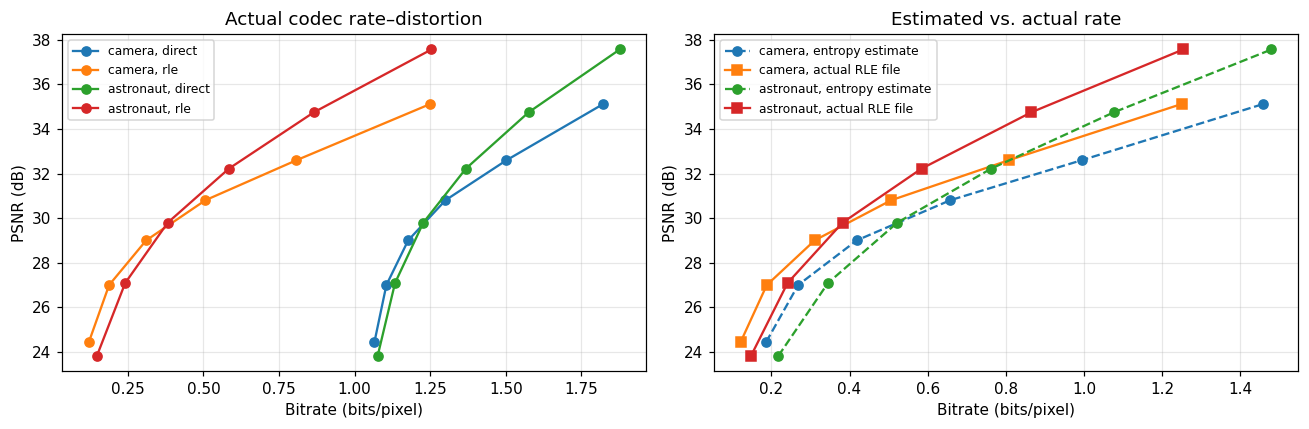

All encoded files decoded successfully; every quantized coefficient recovered exactly.


In [8]:
codec_rows=[]
for name,x in images.items():
    ref_bytes=(OUT/'images'/f'{name}_original.png').stat().st_size
    source_bytes=next(r['source_file_bytes'] for r in image_records if r['image']==name)
    for q in QUALITY_SCALES:
        Q=scaled_q(q); k=quantize_dct(DCTS[name],Q)
        for mode in ['direct','rle']:
            blob,stats=encode_coeffs(k,Q,x.shape,mode)
            path=OUT/'bitstreams'/f'{name}_q{q}_{mode}.ljc'
            path.write_bytes(blob)
            # Decode from actual saved file, rather than in-memory coefficients.
            y,decoded,h=decode_bitstream(path.read_bytes())
            assert np.array_equal(k,decoded), 'Entropy round trip failed'
            assert np.array_equal(y,reconstruct(k,Q,x.shape)), 'Reconstruction mismatch'
            save_image(y,f'{name}_codec_q{q}_{mode}')
            codec_rows.append({'image':name,'q_scale':q,'coding':mode,
                'compressed_bytes':len(blob),'raw_original_bytes':x.size,
                'reference_png_bytes':ref_bytes,'raw_compression_ratio':x.size/len(blob),
                'png_file_compression_ratio':ref_bytes/len(blob),
                'uploaded_source_file_ratio':None if source_bytes is None else source_bytes/len(blob),
                'actual_bpp':8*len(blob)/x.size,'PSNR_dB':psnr(x,y),'SSIM':ssim(x,y),
                'quantized_coefficients_exact':True,**stats})
codec_table=pd.DataFrame(codec_rows)
codec_table.to_csv(OUT/'tables/S7_codec_results.csv',index=False)
display(codec_table[['image','q_scale','coding','compressed_bytes','raw_compression_ratio',
                     'png_file_compression_ratio','actual_bpp','PSNR_dB','SSIM']].round(4))
fig,axs=plt.subplots(1,2,figsize=(12,4))
for name in images:
    for mode in ['direct','rle']:
        t=codec_table[(codec_table.image==name)&(codec_table.coding==mode)].sort_values('actual_bpp')
        axs[0].plot(t.actual_bpp,t.PSNR_dB,'-o',label=f'{name}, {mode}')
    t=rd_table[rd_table.image==name].sort_values('estimated_bpp')
    axs[1].plot(t.estimated_bpp,t.PSNR_dB,'--o',label=f'{name}, entropy estimate')
    t=codec_table[(codec_table.image==name)&(codec_table.coding=='rle')].sort_values('actual_bpp')
    axs[1].plot(t.actual_bpp,t.PSNR_dB,'-s',label=f'{name}, actual RLE file')
for ax in axs:
    ax.set(xlabel='Bitrate (bits/pixel)',ylabel='PSNR (dB)'); ax.grid(alpha=.3); ax.legend(fontsize=8)
axs[0].set_title('Actual codec rate–distortion'); axs[1].set_title('Estimated vs. actual rate')
savefig('S7_actual_codec_rate_distortion')
print('All encoded files decoded successfully; every quantized coefficient recovered exactly.')

## Section 8 — Export everything for the report
The ZIP contains processed originals, unmodified reconstructed pixels, figures, numerical CSVs, quantization matrices, actual compressed bitstreams, the blind comparison and empty/filled ranking form, software versions, and an execution checklist. Figures use display layouts; they do not replace or invent experimental pixel data.

The exported results are available in the `results/` folder of this repository. The notebook also retains its saved execution outputs. The report must stay within **5 pages**, interpret each section in 2–5 sentences, include representative code snippets, and end with a 5–8-sentence reflection. Real subjective rankings can be provided later if still pending.

In [9]:
checklist={
 'S3_uniform_quantizer_and_all_bit_depths':'complete',
 'S3_images_errors_histograms':'complete',
 'S4_block_DCT_quantization_IDCT_matrices':'complete',
 'S5_MSE_PSNR_entropy_bpp_RD_curves':'complete',
 'S6_SSIM_and_metric_comparison':'complete',
 'S6_subjective_materials':'complete; inspect artifact differences before assessment',
 'S6_real_subjective_rankings':f'{subjective_n} valid participants' if subjective_n else 'PENDING — no human responses',
 'S7_encoder_decoder_real_files_ratios_metrics':'complete; exact entropy round trips verified',
 'S8_report':'not yet written; use actual results and observations'}
(OUT/'task_checklist.json').write_text(json.dumps(checklist,indent=2))
readme = """DT096A Lab 3 experiment outputs
================================
Tables: CSV numerical results; metrics use processed grayscale originals.
Images: originals and reconstructed PNGs, with no display contrast rescaling.
Figures: labeled grids, histograms, energy maps, and rate-distortion curves.
Bitstreams: self-contained custom LJC1 files, not standard JPEG files.
Subjective: show only blind_comparison.png or A/B/C/D.png to participants.
Keep PRIVATE_condition_key.json hidden until rankings are collected.
Fill rankings_template.csv with genuine anonymous responses (1 best, 4 worst).
No human results are invented. A blank form means this task remains pending.
The paired images use different matrices; visually verify their artifact differences.
Raw compression ratios and PNG-reference file ratios use different baselines.
Actual file bpp includes JSON metadata, Huffman frequencies, and padding.
The entropy-based bpp is a separate estimate and excludes metadata.
Code uses standard libraries listed in environment.json and ChatGPT assistance.
Report limit: 5 pages; 2–5 sentences per section; 1–2 code snippets per section;
separate 5–8-sentence reflection. Do not write conclusions without inspecting outputs.
"""
(OUT/'README.txt').write_text(readme)
archive=shutil.make_archive(str(OUT.resolve()),'zip',root_dir=OUT.parent,base_dir=OUT.name)
print('\nTASK STATUS')
for task,status in checklist.items(): print(task,':',status)
print(f'\nSaved: {archive}\nZIP size: {Path(archive).stat().st_size/1024**2:.2f} MB')
if AUTO_DOWNLOAD:
    try:
        from google.colab import files
        files.download(archive)
    except ImportError:
        print('Outside Colab: download the ZIP from your notebook file browser.')
print('Send the ZIP back for the report; supply genuine subjective rankings when available.')


TASK STATUS
S3_uniform_quantizer_and_all_bit_depths : complete
S3_images_errors_histograms : complete
S4_block_DCT_quantization_IDCT_matrices : complete
S5_MSE_PSNR_entropy_bpp_RD_curves : complete
S6_SSIM_and_metric_comparison : complete
S6_subjective_materials : complete; inspect artifact differences before assessment
S6_real_subjective_rankings : PENDING — no human responses
S7_encoder_decoder_real_files_ratios_metrics : complete; exact entropy round trips verified
S8_report : not yet written; use actual results and observations

Saved: /content/DT096A_Lab3_results.zip
ZIP size: 12.55 MB


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Send the ZIP back for the report; supply genuine subjective rankings when available.


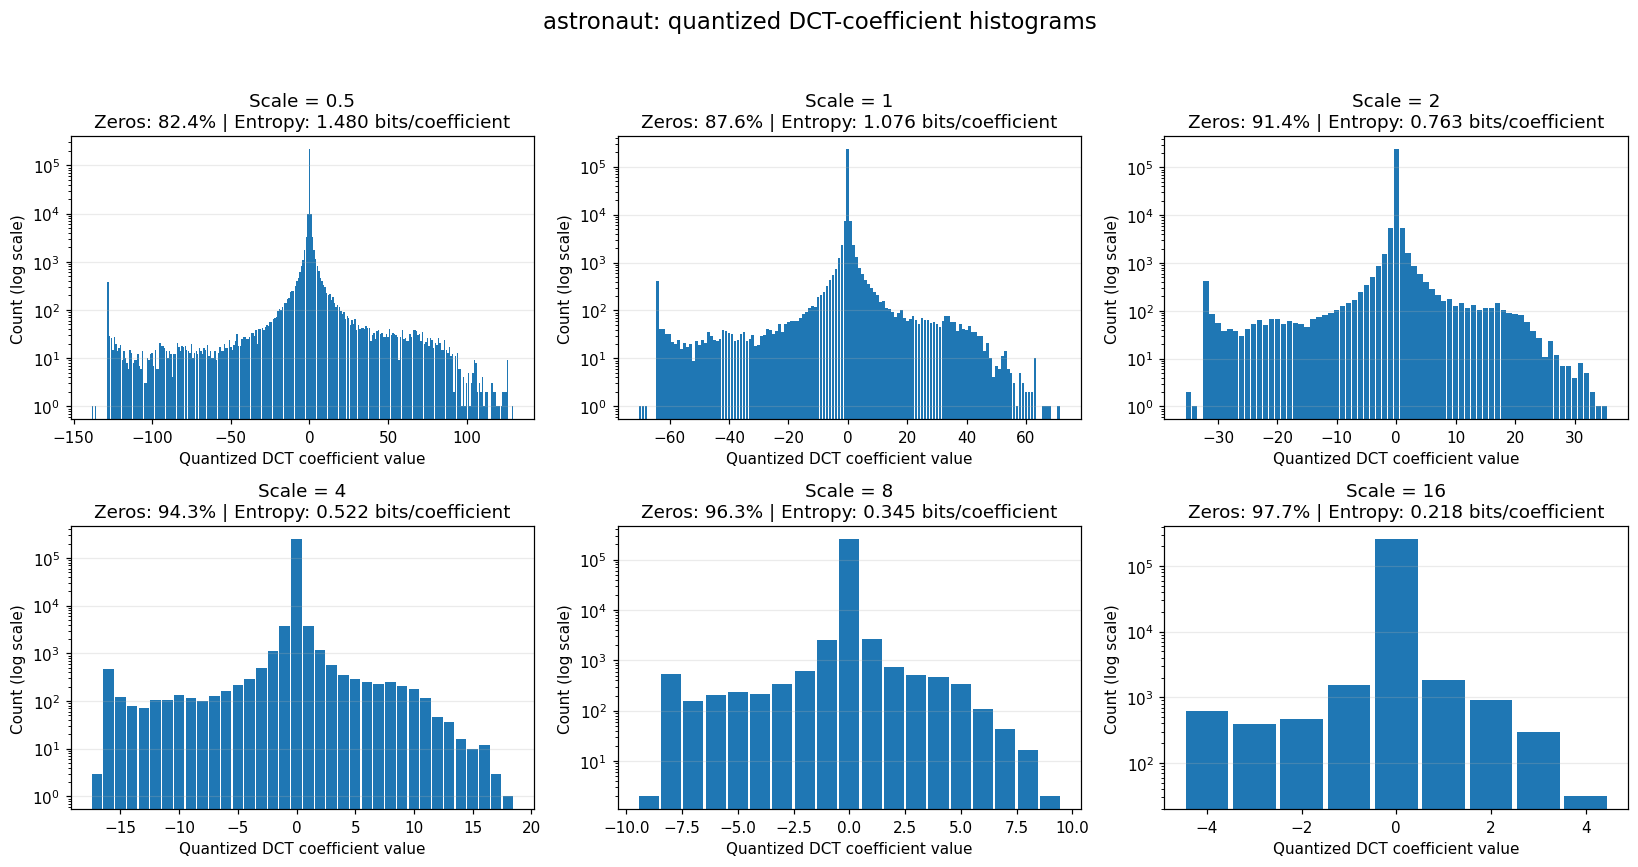

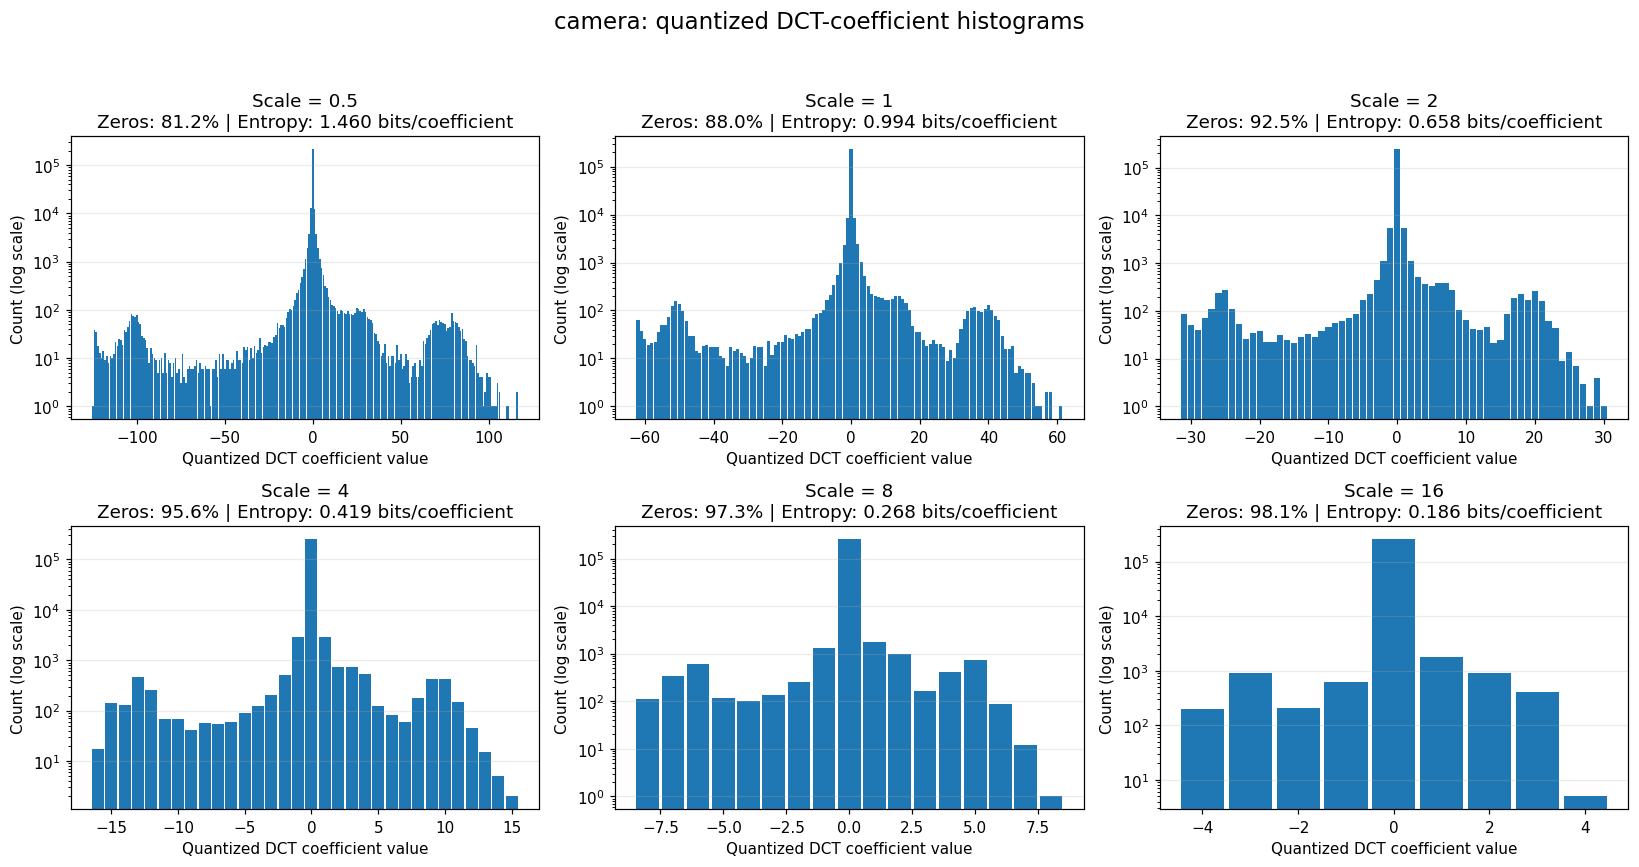

Done: coefficient counts, entropy and zero fractions agree.
Added histogram figures and CSV tables.
Ranking images were preserved.
Updated ZIP: /content/DT096A_Lab3_results_updated.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [10]:
# EXTRA CELL: export quantized DCT-coefficient histograms
# Run after the existing notebook has finished.

from pathlib import Path
import csv
import json
import math
import shutil
import matplotlib.pyplot as plt

# Find the existing results folder.
candidates = [
    Path.cwd() / "DT096A_Lab3_results",
    Path("/content/DT096A_Lab3_results"),
]
ROOT = next(
    (p for p in candidates
     if (p / "tables/S5_S6_rate_distortion.csv").exists()),
    None,
)

if ROOT is None:
    raise FileNotFoundError(
        "DT096A_Lab3_results was not found. "
        "Run the existing notebook first, then run this cell."
    )

with open(ROOT / "tables/S5_S6_rate_distortion.csv") as f:
    results = list(csv.DictReader(f))

histogram_dir = ROOT / "tables/DCT_coefficient_histograms"
histogram_dir.mkdir(parents=True, exist_ok=True)
(ROOT / "figures").mkdir(exist_ok=True)

summary = []

for image_name in sorted({r["image"] for r in results}):
    rows = sorted(
        [r for r in results if r["image"] == image_name],
        key=lambda r: float(r["q_scale"]),
    )

    ncols = 3
    nrows = math.ceil(len(rows) / ncols)
    fig, axes = plt.subplots(
        nrows, ncols,
        figsize=(15, 4 * nrows),
        squeeze=False,
    )

    for ax, row in zip(axes.flat, rows):
        scale = float(row["q_scale"])
        bitstream = (
            ROOT / "bitstreams"
            / f"{image_name}_q{scale:g}_direct.ljc"
        )

        # The direct-coded file stores exact coefficient frequencies.
        with open(bitstream, "rb") as f:
            if f.read(4) != b"LJC1":
                raise ValueError(f"Unexpected file format: {bitstream.name}")
            header_size = int.from_bytes(f.read(4), "big")
            header = json.loads(f.read(header_size).decode("utf-8"))

        if header["mode"] != "direct":
            raise ValueError("This cell requires direct-coded bitstreams.")

        symbols = [int(v) for v in header["symbols"]]
        counts = [int(v) for v in header["frequencies"]]
        total = sum(counts)

        assert total == int(row["coefficient_count"]), (
            f"Coefficient count mismatch: {bitstream.name}"
        )

        probabilities = [count / total for count in counts]
        entropy = -sum(
            p * math.log2(p) for p in probabilities if p > 0
        )
        zero_fraction = sum(
            count for value, count in zip(symbols, counts) if value == 0
        ) / total

        # Confirm agreement with the existing numerical results.
        assert math.isclose(
            entropy,
            float(row["entropy_bits_per_coefficient"]),
            abs_tol=1e-8,
        ), f"Entropy mismatch: {bitstream.name}"

        assert math.isclose(
            zero_fraction,
            float(row["zero_fraction"]),
            abs_tol=1e-8,
        ), f"Zero-fraction mismatch: {bitstream.name}"

        csv_path = histogram_dir / f"{image_name}_q{scale:g}.csv"
        with open(csv_path, "w", newline="") as f:
            writer = csv.writer(f)
            writer.writerow(["quantized_coefficient", "count", "probability"])
            writer.writerows(zip(symbols, counts, probabilities))

        ax.bar(symbols, counts, width=0.9)
        ax.set_yscale("log")
        ax.set_xlabel("Quantized DCT coefficient value")
        ax.set_ylabel("Count (log scale)")
        ax.set_title(
            f"Scale = {scale:g}\n"
            f"Zeros: {100 * zero_fraction:.1f}% | "
            f"Entropy: {entropy:.3f} bits/coefficient"
        )
        ax.grid(axis="y", alpha=0.25)

        summary.append({
            "image": image_name,
            "q_scale": scale,
            "coefficient_count": total,
            "zero_fraction": zero_fraction,
            "entropy_bits_per_coefficient": entropy,
        })

    for ax in list(axes.flat)[len(rows):]:
        ax.set_visible(False)

    fig.suptitle(
        f"{image_name}: quantized DCT-coefficient histograms",
        fontsize=15,
    )
    fig.tight_layout(rect=(0, 0, 1, 0.95))
    fig.savefig(
        ROOT / "figures" / f"S5_{image_name}_DCT_histograms.png",
        dpi=180,
        bbox_inches="tight",
    )
    plt.show()
    plt.close(fig)

with open(ROOT / "tables/S5_DCT_histogram_summary.csv", "w", newline="") as f:
    writer = csv.DictWriter(f, fieldnames=list(summary[0]))
    writer.writeheader()
    writer.writerows(summary)

# Create the updated ZIP outside the results folder.
zip_path = shutil.make_archive(
    str(ROOT.parent / "DT096A_Lab3_results_updated"),
    "zip",
    root_dir=ROOT.parent,
    base_dir=ROOT.name,
)

print("Done: coefficient counts, entropy and zero fractions agree.")
print("Added histogram figures and CSV tables.")
print("Ranking images were preserved.")
print("Updated ZIP:", zip_path)

# Download automatically in Google Colab.
try:
    from google.colab import files
except ImportError:
    print("Download the ZIP from the path shown above.")
else:
    files.download(zip_path)